In [1]:
!pip -q install datasets[audio] librosa soundfile scikit-learn pandas matplotlib seaborn

In [2]:
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, concatenate_datasets
from collections import Counter
from tqdm.auto import tqdm

np.random.seed(42)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [3]:
dfadd = load_dataset(
    "SpeechAntiSpoofingBenchmarks/DFADD",
    split="test"
)

print("======================================")
print("VOICEGUARD - DFADD DATASET")
print("======================================")
print("Total samples:", len(dfadd))
print("Columns:", dfadd.column_names)
print("Class distribution:", Counter(dfadd["label"]))

README.md:   0%|          | 0.00/3.70k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  239MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/3755 [00:00<?, ? examples/s]

VOICEGUARD - DFADD DATASET
Total samples: 3755
Columns: ['path', 'audio', 'label', 'notes']
Class distribution: Counter({1: 3000, 0: 755})


In [4]:
bonafide = dfadd.filter(lambda x: x["label"] == 0)
spoof = dfadd.filter(lambda x: x["label"] == 1)

spoof = spoof.shuffle(seed=42).select(
    range(len(bonafide))
)

balanced_dataset = concatenate_datasets([
    bonafide,
    spoof
]).shuffle(seed=42)

print("Bonafide:", len(bonafide))
print("Spoof:", len(spoof))
print("Balanced total:", len(balanced_dataset))
print("Distribution:", Counter(balanced_dataset["label"]))

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3755 [00:00<?, ? examples/s]

Bonafide: 755
Spoof: 755
Balanced total: 1510
Distribution: Counter({0: 755, 1: 755})


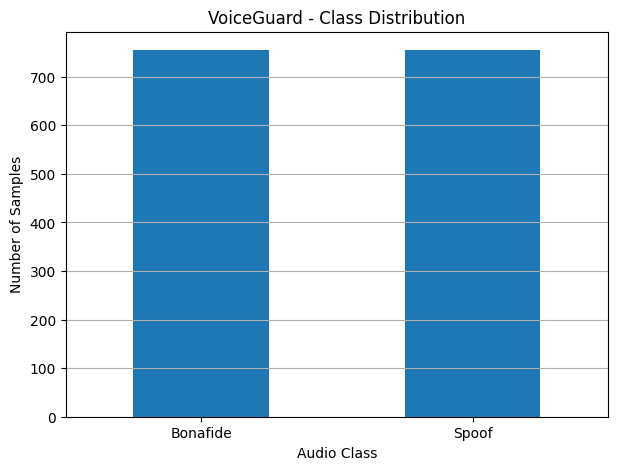

In [5]:
class_counts = pd.Series(
    balanced_dataset["label"]
).map({
    0: "Bonafide",
    1: "Spoof"
}).value_counts()

plt.figure(figsize=(7,5))
class_counts.plot(kind="bar")
plt.title("VoiceGuard - Class Distribution")
plt.xlabel("Audio Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [6]:
def extract_features(audio_data, sr=16000):
    signal = np.asarray(audio_data, dtype=np.float32)

    if len(signal) == 0:
        return None

    signal = signal / (np.max(np.abs(signal)) + 1e-8)

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=40
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    zcr = np.mean(
        librosa.feature.zero_crossing_rate(signal)
    )

    spectral_centroid = np.mean(
        librosa.feature.spectral_centroid(
            y=signal,
            sr=sr
        )
    )

    spectral_bandwidth = np.mean(
        librosa.feature.spectral_bandwidth(
            y=signal,
            sr=sr
        )
    )

    rms = np.mean(
        librosa.feature.rms(y=signal)
    )

    return np.concatenate([
        mfcc_mean,
        mfcc_std,
        [zcr],
        [spectral_centroid],
        [spectral_bandwidth],
        [rms]
    ])

In [7]:
X_features = []
y_labels = []

for i in tqdm(range(len(balanced_dataset))):
    audio = balanced_dataset[i]["audio"]

    features = extract_features(
        audio["array"],
        audio["sampling_rate"]
    )

    if features is not None:
        X_features.append(features)
        y_labels.append(
            balanced_dataset[i]["label"]
        )

X_features = np.array(
    X_features,
    dtype=np.float32
)

y_labels = np.array(
    y_labels,
    dtype=np.int32
)

print("Feature matrix:", X_features.shape)
print("Labels:", y_labels.shape)

  0%|          | 0/1510 [00:00<?, ?it/s]

Feature matrix: (1510, 84)
Labels: (1510,)


In [8]:
feature_names = (
    [f"MFCC_Mean_{i+1}" for i in range(40)] +
    [f"MFCC_Std_{i+1}" for i in range(40)] +
    [
        "Zero_Crossing_Rate",
        "Spectral_Centroid",
        "Spectral_Bandwidth",
        "RMS_Energy"
    ]
)

feature_df = pd.DataFrame(
    X_features,
    columns=feature_names
)

display(feature_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
MFCC_Mean_1,1510.0,-292.509674,49.518219,-452.465820,-326.969818,-291.448151,-255.071426,-181.614304
MFCC_Mean_2,1510.0,84.586227,12.679760,31.389460,76.743805,86.150932,92.927246,124.515976
MFCC_Mean_3,1510.0,4.877990,10.405714,-28.346956,-3.243381,4.582713,12.222046,37.937950
MFCC_Mean_4,1510.0,32.467133,8.364909,5.347472,26.554923,32.737803,38.066693,62.363964
MFCC_Mean_5,1510.0,0.827137,7.896750,-20.786469,-3.621109,1.250052,6.283706,21.234159
...,...,...,...,...,...,...,...,...
MFCC_Std_40,1510.0,4.572742,1.296226,2.294450,3.675468,4.290883,5.168388,13.875310
Zero_Crossing_Rate,1510.0,0.085446,0.028085,0.018028,0.065106,0.085131,0.104431,0.201610
Spectral_Centroid,1510.0,1386.239014,279.679138,543.713623,1185.781006,1394.626404,1599.779877,2345.210449
Spectral_Bandwidth,1510.0,1499.122803,120.827087,1066.860352,1420.077942,1496.086182,1572.936432,2065.410400


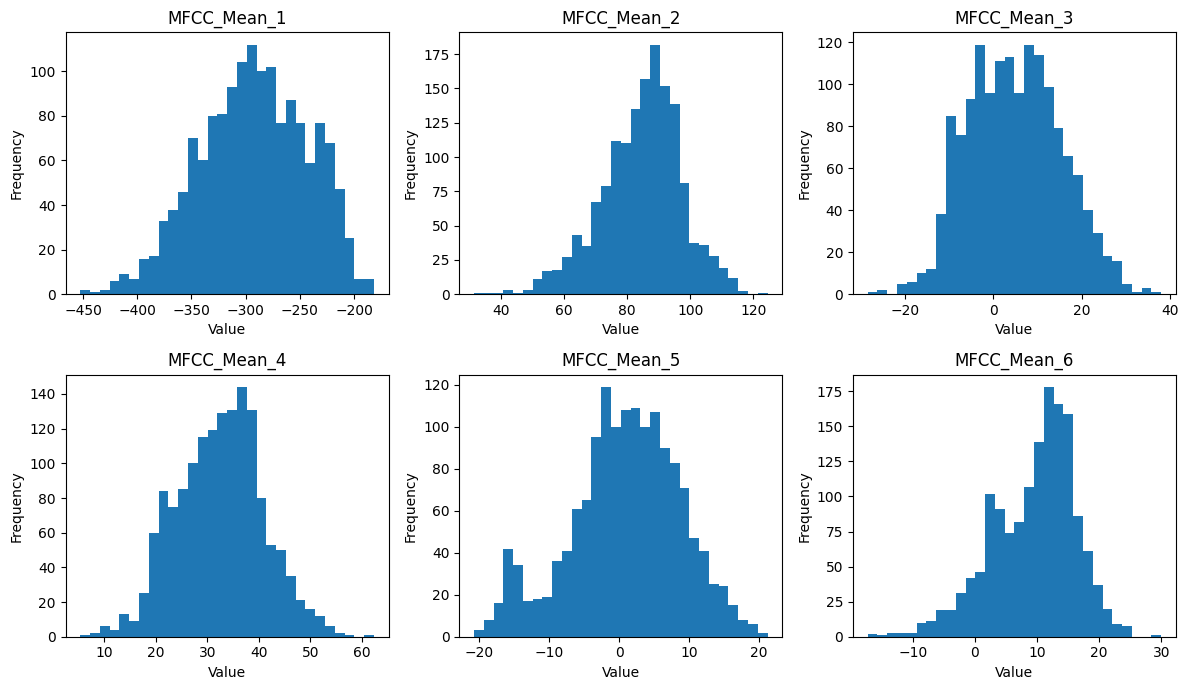

In [9]:
plt.figure(figsize=(12,7))

for i in range(6):
    plt.subplot(2,3,i+1)
    plt.hist(X_features[:,i], bins=30)
    plt.title(feature_names[i])
    plt.xlabel("Value")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

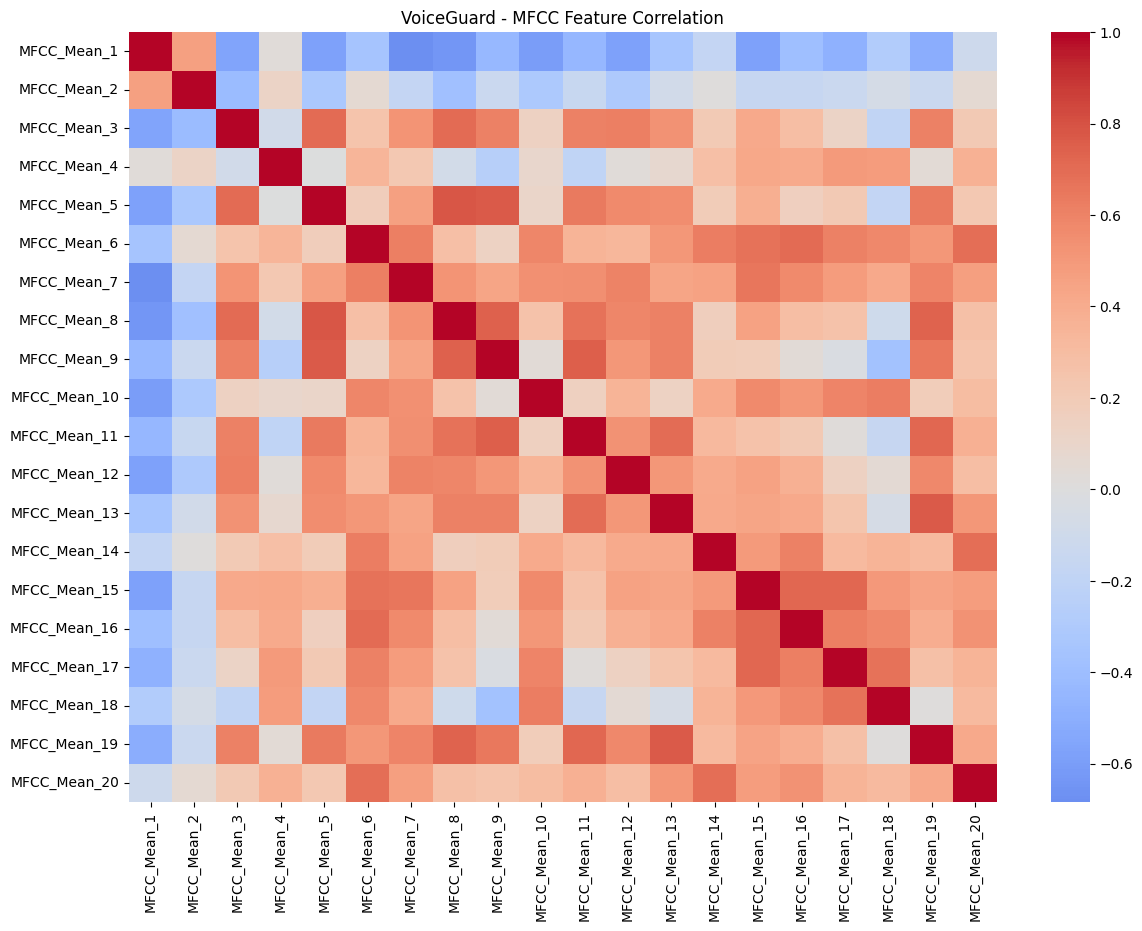

In [10]:
plt.figure(figsize=(14,10))

sns.heatmap(
    feature_df.iloc[:, :20].corr(),
    cmap="coolwarm",
    center=0
)

plt.title("VoiceGuard - MFCC Feature Correlation")
plt.show()

In [11]:
eda_summary = pd.DataFrame({
    "Observation": [
        "Dataset is balanced",
        "Total samples",
        "Audio features",
        "Bonafide samples",
        "Spoof samples",
        "Missing values",
        "Infinite values"
    ],
    "Value": [
        "Yes",
        len(y_labels),
        X_features.shape[1],
        np.sum(y_labels == 0),
        np.sum(y_labels == 1),
        np.isnan(X_features).sum(),
        np.isinf(X_features).sum()
    ]
})

display(eda_summary)

,Observation,Value
0,Dataset is balanced,Yes
1,Total samples,1510
2,Audio features,84
3,Bonafide samples,755
4,Spoof samples,755
5,Missing values,0
6,Infinite values,0
